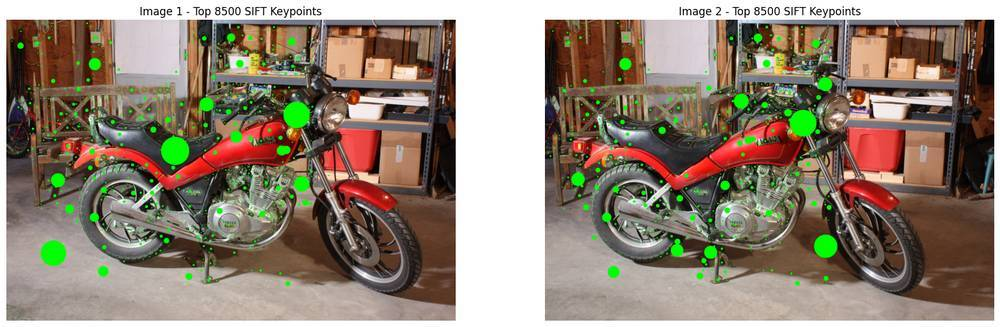


--- RANSAC Results ---
Total matches (before ratio test): 11761
Matches after Lowe's ratio test: 4056


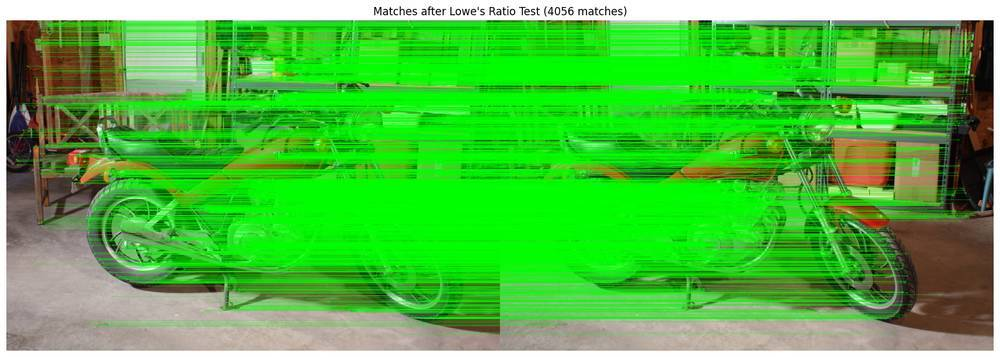

Total matches passed to RANSAC: 4056
Number of INLIERS: 3710
Number of OUTLIERS: 346
Percentage of matches surviving RANSAC: 91.47%


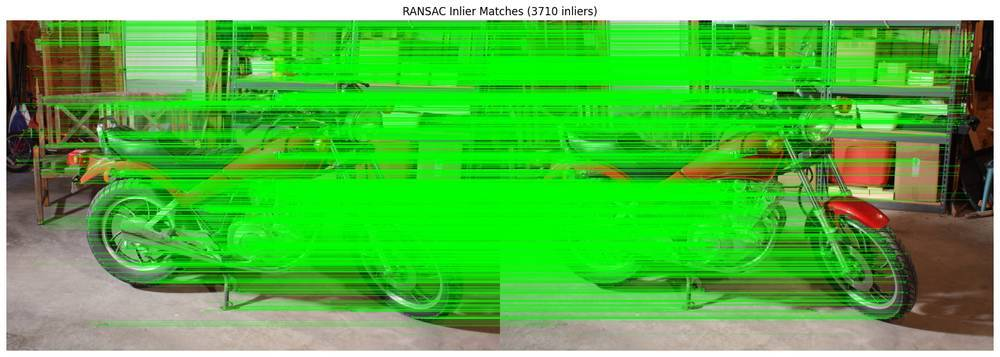


--- Stage 3 Results ---
Estimated Fundamental Matrix (F_CLEAN):
[[ 1.92887980e-07 -7.64392035e-04  5.17886533e-01]
 [ 7.47526823e-04 -6.83253203e-05 -1.10239441e+01]
 [-5.08557994e-01  1.10539002e+01  1.00000000e+00]]


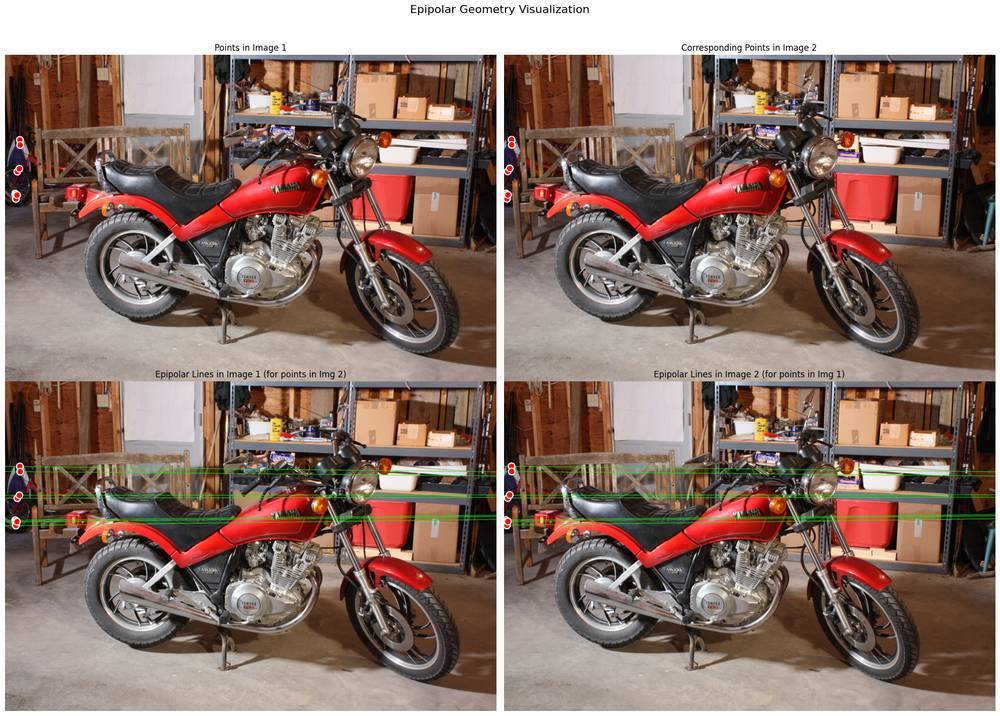


--- Stage 4 Results ---
Camera Intrinsic Matrix (K):
[[3.997684e+03 0.000000e+00 1.176728e+03]
 [0.000000e+00 3.997684e+03 1.011728e+03]
 [0.000000e+00 0.000000e+00 1.000000e+00]]

Estimated Essential Matrix (E):
[[ 3.08263488e+00 -1.22161140e+04 -1.02038212e+03]
 [ 1.19465830e+04 -1.09193956e+03 -4.08300856e+04]
 [ 9.91276918e+02  4.03178105e+04 -4.74642482e+01]]

Relative Rotation (R):
[[ 0.99995868 -0.00287278 -0.0086248 ]
 [ 0.00276086  0.99991219 -0.01296075]
 [ 0.00866128  0.01293641  0.99987881]]

Relative Translation (t) (normalized):
[[-0.95693428]
 [ 0.02425098]
 [-0.28928996]]

--- Stage 5 Results ---
P1 (Camera 1 Projection Matrix):
[[3.997684e+03 0.000000e+00 1.176728e+03 0.000000e+00]
 [0.000000e+00 3.997684e+03 1.011728e+03 0.000000e+00]
 [0.000000e+00 0.000000e+00 1.000000e+00 0.000000e+00]]

P2 (Camera 2 Projection Matrix):
[[ 4.00771078e+03  3.73814413e+00  1.14210616e+03 -4.16593644e+03]
 [ 1.97999155e+01  4.01042110e+03  9.59792392e+02 -1.95734997e+02]
 [ 8.6612786

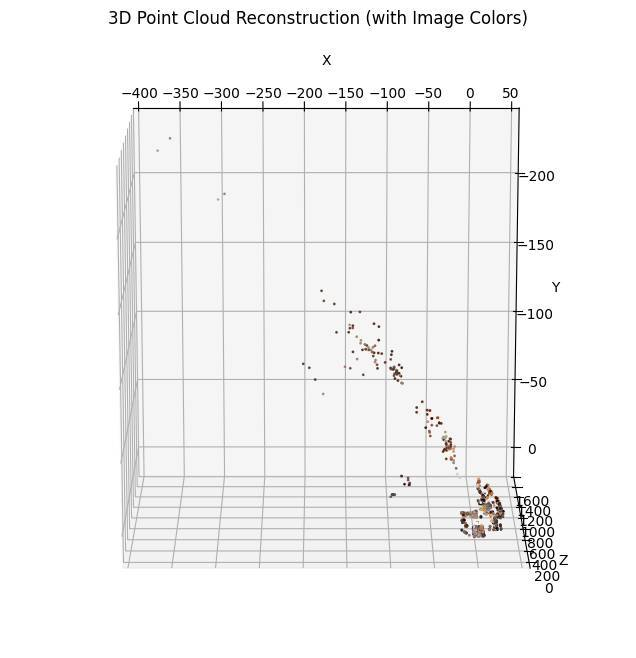


Mean Reprojection Error (Image 1): 0.3852 pixels
Mean Reprojection Error (Image 2): 0.3888 pixels
**Total Mean Reprojection Error:** 0.3870 pixels


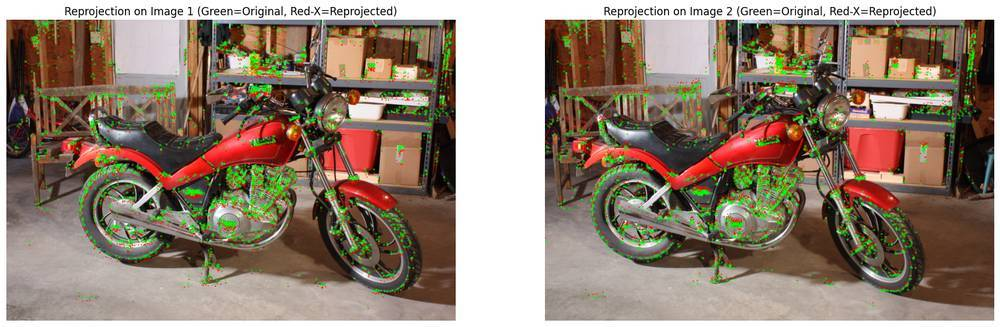

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import re
import sys

# --- Helper function for 3D plotting ---
def plot_3d_points(points_3d, colors):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(points_3d[:, 0], points_3d[:, 1], points_3d[:, 2], 
               c=colors / 255.0, s=1)
    ax.set_title("3D Point Cloud Reconstruction (with Image Colors)")
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.view_init(elev=-75, azim=-90)
    plt.show()

# --- Helper function for epiline drawing ---
def draw_epilines(img1, img2, lines, pts1, pts2):
    img1_out, img2_out = img1.copy(), img2.copy()
    h, w = img1.shape[:2]
    line_color = (0, 255, 0)
    point_fill_color = (0, 0, 255)
    point_border_color = (255, 255, 255)
    radius = 20
    border_thickness = 6
    
    for line, pt1, pt2 in zip(lines, pts1, pts2):
        a, b, c = line
        if b == 0: continue
        x0, y0 = 0, int(-c / b)
        x1, y1 = w, int(-(a * w + c) / b)
        
        img2_out = cv2.line(img2_out, (x0, y0), (x1, y1), line_color, 2)
        pt1_int = tuple(int(c) for c in pt1)
        pt2_int = tuple(int(c) for c in pt2)
        
        img1_out = cv2.circle(img1_out, pt1_int, radius, point_fill_color, -1)
        img2_out = cv2.circle(img2_out, pt2_int, radius, point_fill_color, -1)
        img1_out = cv2.circle(img1_out, pt1_int, radius, point_border_color, border_thickness)
        img2_out = cv2.circle(img2_out, pt2_int, radius, point_border_color, border_thickness)
        
    return img1_out, img2_out

# --- Helper function for reprojection drawing ---
def draw_reprojections(img, pts_original, pts_reprojected):
    img_out = img.copy()
    for orig, reproj in zip(pts_original, pts_reprojected):
        orig_int = (int(orig[0]), int(orig[1]))
        reproj_int = (int(reproj[0]), int(reproj[1]))
        img_out = cv2.circle(img_out, orig_int, 5, (0, 255, 0), 2)
        img_out = cv2.drawMarker(img_out, reproj_int, (0, 0, 255), 
                                 markerType=cv2.MARKER_TILTED_CROSS, 
                                 markerSize=5, thickness=2)
    return img_out

# --- 0. Define File Paths ---
data_dir = 'E:/Aidin/Universities/Amirkabir (Master)/Lessons/My-Terms/Term 4/3D Computer Vision/Assignments/HW2/Answer/Data/Motorcycle-perfect/'
img_path1 = data_dir + 'im0.png'
img_path2 = data_dir + 'im1.png'
calib_file = data_dir + 'calib.txt'

# =================================================================
# --- STAGE 1: FEATURE DETECTION
# =================================================================
img1_bgr = cv2.imread(img_path1)
img2_bgr = cv2.imread(img_path2)

if img1_bgr is None or img2_bgr is None:
    print(f"CRITICAL ERROR: Could not load images from {data_dir}")
    sys.exit()
else:
    img1_gray = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2GRAY)
    img2_gray = cv2.cvtColor(img2_bgr, cv2.COLOR_BGR2GRAY)

    sift = cv2.SIFT_create()
    kp1, des1 = sift.detectAndCompute(img1_gray, None)
    kp2, des2 = sift.detectAndCompute(img2_gray, None)
    
    # --- 1.1: Visualize Keypoints (as requested) ---
    NUM_FEATURES_TO_DRAW = 8500
    RADIUS_SCALE_FACTOR = 0.5
    
    img1_keypoints_style = img1_bgr.copy()
    img2_keypoints_style = img2_bgr.copy()
    green_color = (0, 255, 0)
    thickness = -1
    
    for kp in kp1[:NUM_FEATURES_TO_DRAW]:
        x, y = int(kp.pt[0]), int(kp.pt[1])
        radius = int((kp.size / 2) * RADIUS_SCALE_FACTOR)
        cv2.circle(img1_keypoints_style, (x, y), max(radius, 1), green_color, thickness)

    for kp in kp2[:NUM_FEATURES_TO_DRAW]:
        x, y = int(kp.pt[0]), int(kp.pt[1])
        radius = int((kp.size / 2) * RADIUS_SCALE_FACTOR)
        cv2.circle(img2_keypoints_style, (x, y), max(radius, 1), green_color, thickness)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
    ax1.imshow(cv2.cvtColor(img1_keypoints_style, cv2.COLOR_BGR2RGB))
    ax1.set_title(f"Image 1 - Top {NUM_FEATURES_TO_DRAW} SIFT Keypoints")
    ax1.axis('off')
    ax2.imshow(cv2.cvtColor(img2_keypoints_style, cv2.COLOR_BGR2RGB))
    ax2.set_title(f"Image 2 - Top {NUM_FEATURES_TO_DRAW} SIFT Keypoints")
    ax2.axis('off')
    plt.show()

    # =================================================================
    # --- STAGE 2: FEATURE MATCHING & RANSAC
    # =================================================================
    bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
    matches_knn = bf.knnMatch(des1, des2, k=2)

    matches_ratio_test = []
    ratio_thresh = 0.75 
    for m, n in matches_knn:
        if m.distance < ratio_thresh * n.distance:
            matches_ratio_test.append(m)
            
    # --- 2.1: Report Counts (as requested) ---
    print("\n--- RANSAC Results ---")
    print(f"Total matches (before ratio test): {len(matches_knn)}")
    print(f"Matches after Lowe's ratio test: {len(matches_ratio_test)}")

    # --- 2.2: Visualize Post-Ratio Matches (as requested) ---
    img_matches_ratio = cv2.drawMatches(img1_bgr, kp1, img2_bgr, kp2, 
                                        matches_ratio_test, None, 
                                        matchColor=(0, 255, 0),
                                        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(20, 10))
    plt.imshow(cv2.cvtColor(img_matches_ratio, cv2.COLOR_BGR2RGB))
    plt.title(f"Matches after Lowe's Ratio Test ({len(matches_ratio_test)} matches)")
    plt.axis('off')
    plt.show()

    if len(matches_ratio_test) > 7:
        pts1 = np.float32([kp1[m.queryIdx].pt for m in matches_ratio_test])
        pts2 = np.float32([kp2[m.trainIdx].pt for m in matches_ratio_test])

        F_CLEAN, mask_CLEAN = cv2.findFundamentalMat(pts1, pts2, 
                                                     method=cv2.FM_RANSAC, 
                                                     ransacReprojThreshold=3.0, 
                                                     confidence=0.99)
        
        if F_CLEAN is not None:
            pts1_inliers = pts1[mask_CLEAN.ravel() == 1]
            pts2_inliers = pts2[mask_CLEAN.ravel() == 1]
            
            # --- 2.3: Report RANSAC Counts (as requested) ---
            num_inliers = np.sum(mask_CLEAN)
            num_outliers = len(mask_CLEAN) - num_inliers
            percent_inliers = (num_inliers / len(mask_CLEAN)) * 100
            
            print(f"Total matches passed to RANSAC: {len(mask_CLEAN)}")
            print(f"Number of INLIERS: {num_inliers}")
            print(f"Number of OUTLIERS: {num_outliers}")
            print(f"Percentage of matches surviving RANSAC: {percent_inliers:.2f}%")

            # --- 2.4: Visualize Inlier Matches (as requested) ---
            img_matches_ransac = cv2.drawMatches(img1_bgr, kp1, img2_bgr, kp2, 
                                                 matches_ratio_test, None, 
                                                 matchColor=(0, 255, 0),
                                                 singlePointColor=None,
                                                 matchesMask=mask_CLEAN.ravel().tolist(),
                                                 flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
            plt.figure(figsize=(20, 10))
            plt.imshow(cv2.cvtColor(img_matches_ransac, cv2.COLOR_BGR2RGB))
            plt.title(f"RANSAC Inlier Matches ({num_inliers} inliers)")
            plt.axis('off')
            plt.show()

            # =================================================================
            # --- STAGE 3: FUNDAMENTAL MATRIX & EPIPOLAR GEOMETRY
            # =================================================================
            
            # --- 3.1: Report F Matrix (as requested) ---
            print("\n--- Stage 3 Results ---")
            print("Estimated Fundamental Matrix (F_CLEAN):")
            print(F_CLEAN)
            
            # --- 3.2: Visualize Epipolar Lines (as requested) ---
            pts1_sample = pts1_inliers[:10]
            pts2_sample = pts2_inliers[:10]
            
            lines_in_img2 = cv2.computeCorrespondEpilines(pts1_sample.reshape(-1, 1, 2), 1, F_CLEAN)
            lines_in_img2 = lines_in_img2.reshape(-1, 3) 
            img1_with_points, img2_with_lines = draw_epilines(img1_bgr, img2_bgr, lines_in_img2, pts1_sample, pts2_sample)

            lines_in_img1 = cv2.computeCorrespondEpilines(pts2_sample.reshape(-1, 1, 2), 2, F_CLEAN)
            lines_in_img1 = lines_in_img1.reshape(-1, 3)
            img2_with_points, img1_with_lines = draw_epilines(img2_bgr, img1_bgr, lines_in_img1, pts2_sample, pts1_sample)

            fig, axes = plt.subplots(2, 2, figsize=(20, 15))
            fig.suptitle("Epipolar Geometry Visualization", fontsize=16)
            axes[0, 0].imshow(cv2.cvtColor(img1_with_points, cv2.COLOR_BGR2RGB))
            axes[0, 0].set_title("Points in Image 1")
            axes[0, 1].imshow(cv2.cvtColor(img2_with_points, cv2.COLOR_BGR2RGB))
            axes[0, 1].set_title("Corresponding Points in Image 2")
            axes[1, 0].imshow(cv2.cvtColor(img1_with_lines, cv2.COLOR_BGR2RGB))
            axes[1, 0].set_title("Epipolar Lines in Image 1 (for points in Img 2)")
            axes[1, 1].imshow(cv2.cvtColor(img2_with_lines, cv2.COLOR_BGR2RGB))
            axes[1, 1].set_title("Epipolar Lines in Image 2 (for points in Img 1)")
            for ax in axes.flat: ax.axis('off')
            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            plt.show()

            # =================================================================
            # --- STAGE 4: ESSENTIAL MATRIX & CAMERA MOTION
            # =================================================================
            print("\n--- Stage 4 Results ---")
            
            K = np.zeros((3, 3))
            try:
                with open(calib_file, 'r') as f:
                    for line in f:
                        if line.startswith('cam0='):
                            match = re.search(r'\[(.*?)\]', line)
                            if match:
                                values = re.split(r'[;\s]+', match.group(1))
                                values = [v for v in values if v]
                                K[0, 0] = float(values[0])
                                K[0, 2] = float(values[2])
                                K[1, 1] = float(values[4])
                                K[1, 2] = float(values[5])
                                K[2, 2] = 1.0
                                break
                # --- 4.1: Report K Matrix (as requested) ---
                print("Camera Intrinsic Matrix (K):")
                print(K)
            except FileNotFoundError:
                print(f"CRITICAL ERROR: calib.txt not found at {calib_file}")
                sys.exit()

            E = K.T @ F_CLEAN @ K
            points, R, t, mask_pose = cv2.recoverPose(E, pts1_inliers, pts2_inliers, K)
            
            # --- 4.2: Report E, R, t (as requested) ---
            print("\nEstimated Essential Matrix (E):")
            print(E)
            print("\nRelative Rotation (R):")
            print(R)
            print("\nRelative Translation (t) (normalized):")
            print(t)

            # =================================================================
            # --- STAGE 5: TRIANGULATION & 3D RECONSTRUCTION
            # =================================================================
            print("\n--- Stage 5 Results ---")
            
            P1 = K @ np.hstack((np.eye(3), np.zeros((3, 1))))
            P2 = K @ np.hstack((R, t))
            
            print("P1 (Camera 1 Projection Matrix):")
            print(P1)
            print("\nP2 (Camera 2 Projection Matrix):")
            print(P2)

            pts1_inliers_t = pts1_inliers.T
            pts2_inliers_t = pts2_inliers.T
            points_4d_hom = cv2.triangulatePoints(P1, P2, pts1_inliers_t, pts2_inliers_t)
            points_3d = (points_4d_hom[:3] / points_4d_hom[3]).T

            # --- 5.1: Visualize 3D Point Cloud (as requested) ---
            colors_rgb = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2RGB)
            pts1_int_coords = pts1_inliers.astype(int)
            point_colors = colors_rgb[pts1_int_coords[:, 1], pts1_int_coords[:, 0]]
            plot_3d_points(points_3d, point_colors)

            # --- 5.2: Calculate Reprojection Error ---
            rvec1, _ = cv2.Rodrigues(np.eye(3))
            tvec1 = np.zeros((3, 1))
            pts1_reprojected, _ = cv2.projectPoints(points_3d, rvec1, tvec1, K, None)
            pts1_reprojected = pts1_reprojected.reshape(-1, 2)
            
            rvec2, _ = cv2.Rodrigues(R)
            tvec2 = t
            pts2_reprojected, _ = cv2.projectPoints(points_3d, rvec2, tvec2, K, None)
            pts2_reprojected = pts2_reprojected.reshape(-1, 2)
            
            error1 = cv2.norm(pts1_inliers, pts1_reprojected, cv2.NORM_L2) / len(pts1_inliers)
            error2 = cv2.norm(pts2_inliers, pts2_reprojected, cv2.NORM_L2) / len(pts2_inliers)
            mean_reprojection_error = (error1 + error2) / 2
            
            # --- 5.3: Report Mean Reprojection Error (as requested) ---
            print(f"\nMean Reprojection Error (Image 1): {error1:.4f} pixels")
            print(f"Mean Reprojection Error (Image 2): {error2:.4f} pixels")
            print(f"**Total Mean Reprojection Error:** {mean_reprojection_error:.4f} pixels")
            
            # --- 5.4: Visualize Reprojections (as requested) ---
            img1_reproj = draw_reprojections(img1_bgr, pts1_inliers, pts1_reprojected)
            img2_reproj = draw_reprojections(img2_bgr, pts2_inliers, pts2_reprojected)
            
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
            ax1.imshow(cv2.cvtColor(img1_reproj, cv2.COLOR_BGR2RGB))
            ax1.set_title("Reprojection on Image 1 (Green=Original, Red-X=Reprojected)")
            ax1.axis('off')
            ax2.imshow(cv2.cvtColor(img2_reproj, cv2.COLOR_BGR2RGB))
            ax2.set_title("Reprojection on Image 2 (Green=Original, Red-X=Reprojected)")
            ax2.axis('off')
            plt.show()

        else:
            print("Error: RANSAC failed to find a Fundamental Matrix. Halting.")
    else:
        print("Error: Not enough matches found to run RANSAC. Halting.")